# The Global Trade Network of Raw Tobacco (2023)

**Revised version of an individual project** for the Network Optimisation and Social Networks course of the
Master's in Data Analytics and Decision Support Systems (ISCAC – Coimbra Business School), originally submitted in September 2024.

Which countries supply the world's raw tobacco, where does it go, and which countries sit at the centre of the trade?
The data is every export of *tobacco, partly or wholly stemmed or stripped* (HS code 240120) reported to UN Comtrade for 2023.
Countries are nodes, and each exporter → importer pair is a directed edge weighted by net weight (tonnes) and value (US$).

Changes from the original version:

1. The full pipeline, from the raw UN Comtrade file to the results, is in this notebook.
2. Trade volumes are used as edge weights in every measure where they matter. In the original, the column was called `Weight` and NetworkX looks for `weight`, so PageRank and Louvain silently ignored it.
3. The connectivity analysis is reinterpreted: the 90 strongly connected components are one core of 54 countries plus 89 single countries, not 90 trading groups.
4. Communities are evaluated with modularity and checked across random seeds.
5. Countries are not removed before computing centrality. The original removed every country outside the 54-country core, which dropped major importers such as the United Arab Emirates, Indonesia and Vietnam.
6. New: concentration of the trade, export/import ratios and export unit values (US$/kg).

## 1. Setup

In [1]:
import json
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection

DATA_DIR, FIG_DIR, RESULTS_DIR = "../data", "../figures", "../results"
SEED = 42

# Fixed categorical order; text never takes the series colour
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
BLUE, GREY, LAND = PALETTE[0], "#8a8984", "#e6e5e0"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "axes.axisbelow": True})
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

## 2. Data

Exports of HS 240120 for 2023, all reporters and partners, extracted from UN Comtrade.
Cleaning steps:

- Remove rows whose partner is the **World** aggregate (`W00`), which double-count the bilateral rows.
- Remove partners that are not a country: **Areas, nes** (`_X`) and **Free Zones** (`X2`).
- Remove rows without net weight.

`S19` (*Other Asia, nes*) is kept: UN Comtrade commonly uses it for Taiwan.

In [2]:
raw = pd.read_csv(f"{DATA_DIR}/comtrade_hs240120_exports_2023.csv")
for c in ["ReporterISO", "PartnerISO"]:
    raw[c] = raw[c].astype(str).str.strip()

steps = {"raw rows": len(raw)}
df = raw[raw["PartnerISO"] != "W00"]; steps["without World aggregates"] = len(df)
df = df[~df["PartnerISO"].isin(["_X", "X2"])]; steps["without unspecified partners"] = len(df)
df = df[df["NetWgt"].notna()]; steps["without missing weight"] = len(df)
pd.Series(steps, name="rows").to_frame()

,rows
raw rows,1088
without World aggregates,1026
without unspecified partners,1021
without missing weight,1020


In [3]:
edges = (
    df.groupby(["ReporterISO", "PartnerISO"], as_index=False)
      .agg(tonnes=("NetWgt", lambda s: s.sum() / 1000), usd=("PrimaryValue", "sum"))
      .rename(columns={"ReporterISO": "exporter", "PartnerISO": "importer"})
)
coords = pd.read_csv(f"{DATA_DIR}/country_coordinates.csv").set_index("iso3")

G = nx.from_pandas_edgelist(edges, "exporter", "importer", ["tonnes", "usd"], create_using=nx.DiGraph())
missing = set(G) - set(coords.index)
assert not missing, f"No coordinates for {missing}"

total_t, total_usd = edges["tonnes"].sum(), edges["usd"].sum()
print(f"{G.number_of_nodes()} countries, {G.number_of_edges():,} trade flows, density {nx.density(G):.3f}")
print(f"{total_t:,.0f} tonnes worth US$ {total_usd / 1e9:.2f} billion")

143 countries, 1,020 trade flows, density 0.050
1,452,477 tonnes worth US$ 8.76 billion


## 3. Who exports, who imports

In [4]:
exports_t = pd.Series(dict(G.out_degree(weight="tonnes")), name="exports_t")
imports_t = pd.Series(dict(G.in_degree(weight="tonnes")), name="imports_t")

def top_share(s, k):
    return s.nlargest(k).sum() / s.sum()

print(f"Top 5 exporters: {top_share(exports_t, 5):.0%} of all tonnes  ({', '.join(exports_t.nlargest(5).index)})")
print(f"Top 5 importers: {top_share(imports_t, 5):.0%} of all tonnes  ({', '.join(imports_t.nlargest(5).index)})")
print(f"Top 10 flows (of {len(edges):,}): {top_share(edges['tonnes'], 10):.0%} of all tonnes")
edges.nlargest(10, "tonnes").assign(share=lambda d: d["tonnes"] / total_t).reset_index(drop=True)

Top 5 exporters: 65% of all tonnes  (BRA, IND, ZWE, CHN, USA)
Top 5 importers: 51% of all tonnes  (BEL, CHN, ARE, IDN, USA)
Top 10 flows (of 1,020): 30% of all tonnes


,exporter,importer,tonnes,usd,share
0,BRA,BEL,"84,094.072","584,326,473.000",0.058
1,ZWE,CHN,"70,182.100","578,271,064.240",0.048
2,IND,BEL,"59,617.960","265,232,481.712",0.041
3,BRA,CHN,"55,341.003","427,473,559.000",0.038
4,TZA,BEL,"29,667.070","162,843,109.300",0.020
5,IND,ARE,"28,475.612","112,542,833.778",0.020
6,MWI,BEL,"28,179.950","147,777,037.880",0.019
7,CHN,IDN,"27,806.256","117,409,017.000",0.019
8,USA,CHN,"24,498.200","226,781,226.000",0.017
9,BRA,USA,"24,017.315","167,613,891.000",0.017


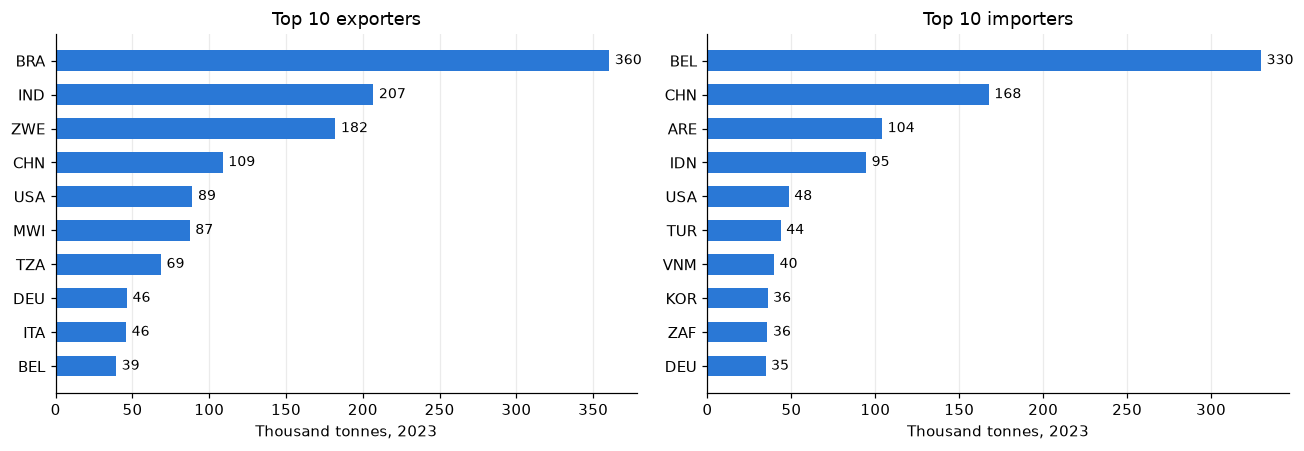

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for ax, s, title in [(axes[0], exports_t, "Top 10 exporters"), (axes[1], imports_t, "Top 10 importers")]:
    top = s.nlargest(10)[::-1] / 1000
    ax.barh(top.index, top.values, color=BLUE, height=0.6)
    for y, v in enumerate(top.values):
        ax.text(v + top.max() * 0.01, y, f"{v:,.0f}", va="center", fontsize=9)
    ax.set_title(title); ax.set_xlabel("Thousand tonnes, 2023"); ax.grid(axis="y", visible=False)
fig.tight_layout(); fig.savefig(f"{FIG_DIR}/top_exporters_importers.png", bbox_inches="tight"); plt.show()

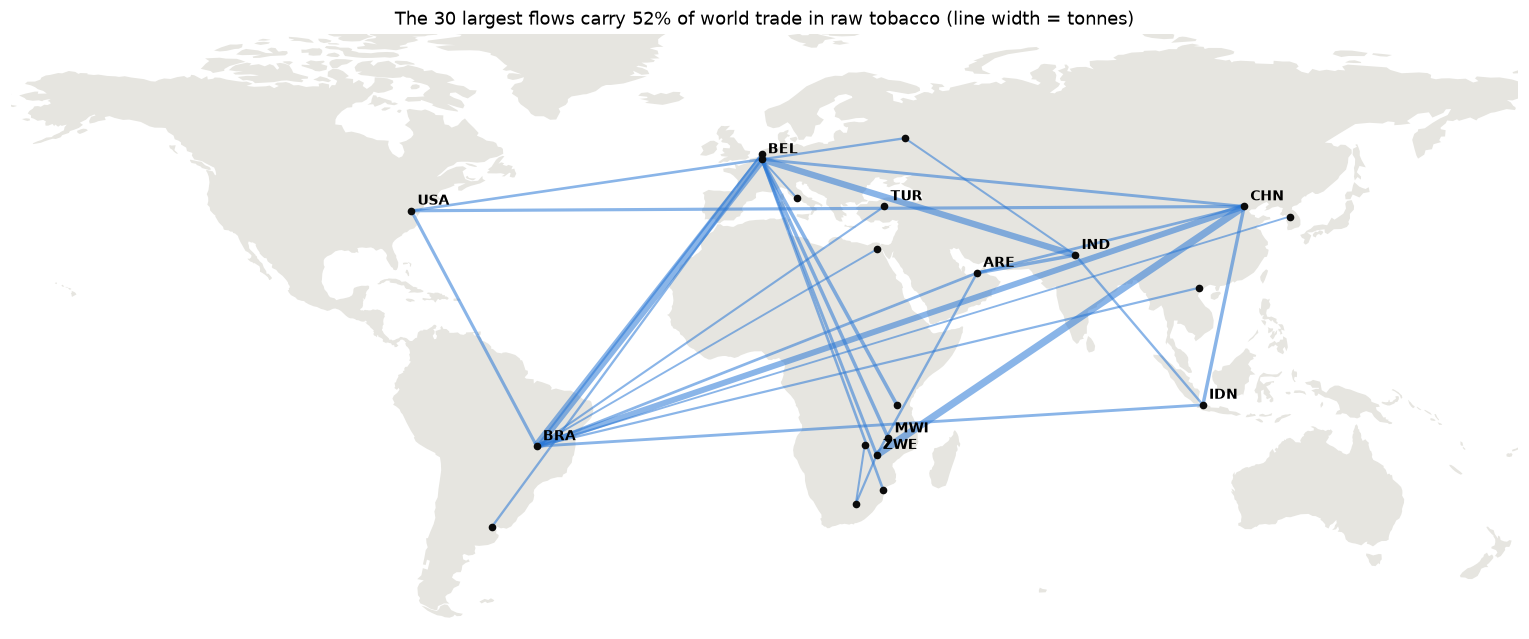

In [6]:
with open(f"{DATA_DIR}/world_land_110m.geojson") as f:
    land = json.load(f)

def draw_land(ax):
    for feat in land["features"]:
        geom = feat["geometry"]
        polys = geom["coordinates"] if geom["type"] == "MultiPolygon" else [geom["coordinates"]]
        for poly in polys:
            ring = np.array(poly[0])
            lon = np.rad2deg(np.unwrap(np.deg2rad(ring[:, 0])))  # rings crossing the antimeridian
            for shift in (-360, 0, 360):
                ax.fill(lon + shift, ring[:, 1], color=LAND, lw=0)
    ax.set_xlim(-170, 180); ax.set_ylim(-58, 80); ax.set_aspect("equal")
    ax.axis("off")

def xy(c):
    return coords.loc[c, "Longitude"], coords.loc[c, "Latitude"]

top_flows = edges.nlargest(30, "tonnes")
segments = [[xy(r.exporter), xy(r.importer)] for r in top_flows.itertuples()]
widths = 0.6 + 5 * top_flows["tonnes"] / top_flows["tonnes"].max()

fig, ax = plt.subplots(figsize=(14, 6.5))
draw_land(ax)
ax.add_collection(LineCollection(segments, linewidths=widths, colors=BLUE, alpha=0.55))
ends = pd.unique(top_flows[["exporter", "importer"]].values.ravel())
ax.scatter([xy(c)[0] for c in ends], [xy(c)[1] for c in ends], s=16, color="#0b0b0b", zorder=3)
for c in exports_t.nlargest(6).index.union(imports_t.nlargest(6).index):
    x, y = xy(c); ax.annotate(c, (x, y), xytext=(4, 4), textcoords="offset points", fontsize=9, weight="bold")
ax.set_title(f"The 30 largest flows carry {top_share(edges['tonnes'], 30):.0%} of world trade in raw tobacco (line width = tonnes)")
fig.tight_layout(); fig.savefig(f"{FIG_DIR}/largest_flows_map.png", bbox_inches="tight"); plt.show()

## 4. Connectivity

A strongly connected component is a set of countries where each one can reach every other one by following trade flows in their direction.

In [7]:
sccs = sorted(nx.strongly_connected_components(G), key=len, reverse=True)
sizes = pd.Series([len(c) for c in sccs])
core = sccs[0]
outside = set(G) - core
only_import = {n for n in outside if G.out_degree(n) == 0}
only_export = {n for n in outside if G.in_degree(n) == 0}

print(f"Weakly connected components: {nx.number_weakly_connected_components(G)}")
print(f"Strongly connected components: {len(sccs)}  ->  one of {len(core)} countries and {int((sizes == 1).sum())} of a single country")
print(f"Outside the core: {len(only_import)} only import, {len(only_export)} only export, "
      f"{len(outside) - len(only_import) - len(only_export)} both import and export but are not in any trade cycle")
print(f"Share of tonnes on flows inside the core: "
      f"{edges[edges.exporter.isin(core) & edges.importer.isin(core)]['tonnes'].sum() / total_t:.0%}")
print("Largest importers outside the core:", ", ".join(imports_t[list(only_import)].nlargest(6).index))

Weakly connected components: 1
Strongly connected components: 90  ->  one of 54 countries and 89 of a single country
Outside the core: 82 only import, 3 only export, 4 both import and export but are not in any trade cycle
Share of tonnes on flows inside the core: 67%
Largest importers outside the core: ARE, IDN, VNM, KOR, RUS, EGY


The 90 components found in the original report are therefore not 90 trading groups. The network has a single core where trade circulates,
and a periphery of countries that sit at the end of the chain, mostly destinations that only import.

## 5. Roles in the network

Measures used, all weighted by tonnes unless stated:

- **Exports and imports** (weighted out- and in-degree).
- **HITS hubs and authorities.** A hub sends large volumes to important destinations; an authority receives large volumes from important suppliers. This fits a directed trade network better than eigenvector centrality.
- **PageRank** on the weighted graph.
- **Betweenness** (unweighted): how often a country lies on the shortest trade path between two others, a proxy for intermediaries.
- **Export/import ratio** and **export unit value** (US$ per kg) to separate producers, processors and destination markets.

In [8]:
W = nx.DiGraph()
W.add_weighted_edges_from(edges[["exporter", "importer", "tonnes"]].itertuples(index=False))
hubs, authorities = nx.hits(W, max_iter=10_000)
pagerank = nx.pagerank(W, weight="weight")
betweenness = nx.betweenness_centrality(G)

exports_usd = edges.groupby("exporter")["usd"].sum()
metrics = pd.DataFrame({
    "exports_t": exports_t, "imports_t": imports_t,
    "partners_out": pd.Series(dict(G.out_degree())), "partners_in": pd.Series(dict(G.in_degree())),
    "hub": pd.Series(hubs), "authority": pd.Series(authorities),
    "pagerank": pd.Series(pagerank), "betweenness": pd.Series(betweenness),
    "in_core": pd.Series({n: n in core for n in G}),
})
metrics["export_import_ratio"] = (metrics["exports_t"] / metrics["imports_t"]).replace(np.inf, np.nan)
metrics["unit_value_usd_kg"] = exports_usd / (metrics["exports_t"] * 1000)
metrics.index.name = "iso3"
metrics.to_csv(f"{RESULTS_DIR}/country_metrics.csv")

rank_cols = ["hub", "authority", "pagerank", "betweenness"]
pd.DataFrame({c: metrics[c].nlargest(8).index for c in rank_cols}, index=range(1, 9))

,hub,authority,pagerank,betweenness
1,BRA,BEL,BEL,USA
2,ZWE,CHN,RUS,BEL
3,IND,ARE,IRN,ITA
4,CHN,IDN,ITA,BRA
5,USA,USA,ARE,IND
6,MWI,VNM,IDN,DEU
7,TZA,KOR,USA,ZWE
8,ARG,TUR,TUR,CHN


In [9]:
big = metrics[(metrics["exports_t"] > 0) & (metrics["imports_t"] > 20_000)].sort_values("export_import_ratio")
big[["exports_t", "imports_t", "export_import_ratio"]].round(2)

,exports_t,imports_t,export_import_ratio
iso3,,,
JOR,21.770,"20,321.130",0.000
NLD,397.660,"30,167.770",0.010
ZAF,"1,710.990","35,751.440",0.050
CHE,"1,006.640","20,667.540",0.050
TUR,"3,419.940","43,628.200",0.080
BEL,"39,358.720","329,742.570",0.120
POL,"6,467.450","34,428.240",0.190
PHL,"9,415.110","25,907.660",0.360
GRC,"13,754.500","25,166.890",0.550


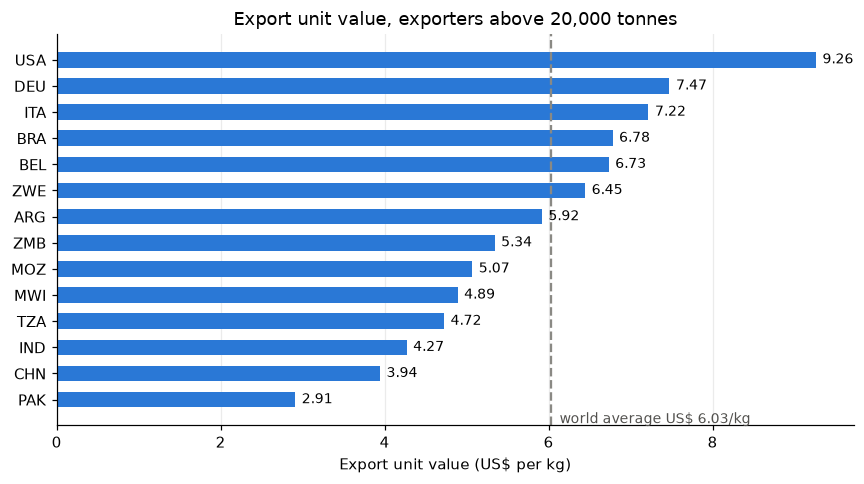

In [10]:
uv = metrics[metrics["exports_t"] > 20_000].sort_values("unit_value_usd_kg")
avg_uv = (edges["usd"].sum() / (edges["tonnes"].sum() * 1000))

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(uv.index, uv["unit_value_usd_kg"], color=BLUE, height=0.6)
ax.axvline(avg_uv, color=GREY, ls="--", lw=1.5)
ax.text(avg_uv + 0.1, -0.9, f"world average US$ {avg_uv:.2f}/kg", color="#52514e", fontsize=9)
for y, v in enumerate(uv["unit_value_usd_kg"]):
    ax.text(v + 0.08, y, f"{v:.2f}", va="center", fontsize=9)
ax.set_xlabel("Export unit value (US$ per kg)")
ax.set_title("Export unit value, exporters above 20,000 tonnes")
ax.grid(axis="y", visible=False)
fig.tight_layout(); fig.savefig(f"{FIG_DIR}/export_unit_values.png", bbox_inches="tight"); plt.show()

## 6. Communities

Louvain is applied to the undirected network, with each pair of countries weighted by the total tonnes traded in both directions.
Louvain is heuristic, so it is run with 50 seeds; the partition with the highest modularity is kept, and the range shows how stable it is.
Modularity (Q) compares the weight inside communities with what would be expected at random: values above about 0.3 usually indicate clear communities.

In [11]:
U = nx.Graph()
for u, v, w in W.edges(data="weight"):
    U.add_edge(u, v, weight=U[u][v]["weight"] + w if U.has_edge(u, v) else w)

runs = []
for s in range(50):
    parts = nx.community.louvain_communities(U, weight="weight", seed=s)
    runs.append((nx.community.modularity(U, parts, weight="weight"), parts))
q = np.array([r[0] for r in runs])
best_q, best = max(runs, key=lambda r: r[0])
print(f"Weighted modularity over 50 seeds: {q.min():.3f} to {q.max():.3f}; "
      f"{sorted({len(r[1]) for r in runs})} communities")

# Same setting as the original report: unweighted, only the 54-country core
core_u = nx.Graph()  # built in a fixed node order so Louvain is reproducible
core_u.add_nodes_from(n for n in G if n in core)
core_u.add_edges_from((a, b) for a, b in G.edges if a in core and b in core)
orig = nx.community.louvain_communities(core_u, seed=SEED)
cross = sum(1 for a, b in core_u.edges if not any(a in c and b in c for c in orig)) / core_u.number_of_edges()
print(f"Original setting: Q = {nx.community.modularity(core_u, orig):.3f}, {cross:.0%} of links cross communities")

Weighted modularity over 50 seeds: 0.192 to 0.210; [5, 6, 7] communities
Original setting: Q = 0.119, 59% of links cross communities


In [12]:
strength = pd.Series(dict(U.degree(weight="weight")))
best = sorted(best, key=lambda c: -strength[list(c)].sum())
community = {n: i + 1 for i, c in enumerate(best) for n in c}
metrics["community"] = pd.Series(community)
metrics.to_csv(f"{RESULTS_DIR}/country_metrics.csv")

within = sum(w for a, b, w in U.edges(data="weight") if community[a] == community[b]) / U.size(weight="weight")
print(f"Best partition: Q = {best_q:.3f}; {within:.0%} of tonnes flow within communities\n")

summary = pd.DataFrame([{
    "community": i + 1, "countries": len(c),
    "tonnes_share": strength[list(c)].sum() / (2 * U.size(weight="weight")),
    "largest members": ", ".join(strength[list(c)].nlargest(8).index),
} for i, c in enumerate(best)]).set_index("community")
summary.to_csv(f"{RESULTS_DIR}/communities.csv")
summary

Best partition: Q = 0.210; 51% of tonnes flow within communities



,countries,tonnes_share,largest members
community,,,
1,39,0.403,"BRA, CHN, ZWE, ARE, IDN, VNM, PAK, EGY"
2,36,0.336,"BEL, IND, MWI, TZA, KOR, ARG, PHL, RUS"
3,37,0.147,"DEU, ITA, TUR, POL, GRC, NLD, BGR, ROU"
4,19,0.065,"USA, MEX, DOM, CAN, GTM, LBN, NIC, UZB"
5,5,0.029,"ZAF, ZMB, CHE, LSO, SWZ"
6,7,0.020,"PRT, FRA, ESP, CIV, SEN, AND, CPV"


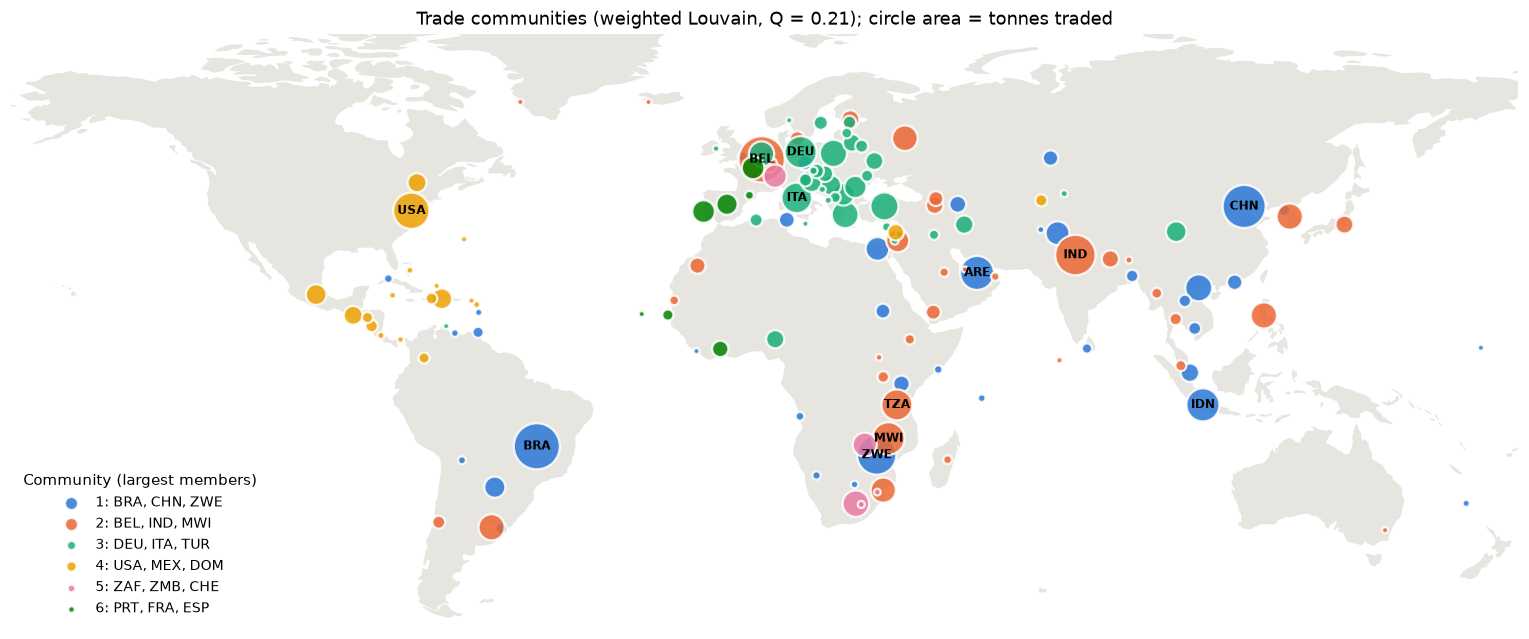

In [13]:
fig, ax = plt.subplots(figsize=(14, 6.5))
draw_land(ax)
size = 15 + 900 * np.sqrt(strength / strength.max())
for i, c in enumerate(best):
    nodes = sorted(c, key=lambda n: -strength[n])
    ax.scatter([xy(n)[0] for n in nodes], [xy(n)[1] for n in nodes], s=size[nodes],
               color=PALETTE[i % len(PALETTE)], alpha=0.85, edgecolor="white", linewidth=1.5,
               label=f"{i + 1}: {', '.join(nodes[:3])}", zorder=3)
for n in strength.nlargest(12).index:
    x, y = xy(n); ax.annotate(n, (x, y), xytext=(0, 0), textcoords="offset points",
                              ha="center", va="center", fontsize=8, weight="bold", zorder=4)
ax.legend(title="Community (largest members)", loc="lower left", frameon=False, fontsize=9, markerscale=0.4)
ax.set_title(f"Trade communities (weighted Louvain, Q = {best_q:.2f}); circle area = tonnes traded")
fig.tight_layout(); fig.savefig(f"{FIG_DIR}/communities_map.png", bbox_inches="tight"); plt.show()

## 7. Conclusions

**A concentrated trade.** 143 countries and 1,020 flows moved 1.45 million tonnes of raw tobacco worth US$ 8.8 billion in 2023.
Five exporters (Brazil, India, Zimbabwe, China and the United States) supplied 65% of the tonnes, five importers (Belgium, China, the United Arab Emirates, Indonesia and the United States) received 51%,
and the 30 largest of the 1,020 flows carried 52% of the volume.

**A core and a periphery.** Trade circulates in both directions only inside a core of 54 countries, which accounts for 67% of the tonnes.
The other 89 countries are at the end of the chain: 82 of them only import, including large markets such as the United Arab Emirates, Indonesia, Vietnam, South Korea, Russia and Egypt.
Restricting the analysis to the core, as the original version did, leaves out about a third of the trade.

**Different roles.** The HITS hubs are the producers (Brazil, Zimbabwe, India, China, the United States) and the main authorities are Belgium and China.
Belgium imports 330 thousand tonnes and exports 39 thousand (ratio 0.12), which points to processing or to its role as an entry point to Europe; this data alone cannot tell which.
Germany, Italy and the United States both import and export, with more exports than imports, and they also have the highest betweenness together with Belgium.

**Prices differ widely.** Export unit values range from US$ 2.91/kg (Pakistan) to US$ 9.26/kg (United States), against a world average of US$ 6.03/kg.
Brazil and Zimbabwe sell above the average, while Malawi, Tanzania, India and China sell below it, which is consistent with differences in leaf type and quality.

**Weak communities.** Weighted Louvain gives a modularity of 0.19 to 0.21 across 50 seeds, and only 51% of the tonnes flow inside communities.
The network is organised around a few large suppliers and buyers rather than closed regional blocs.
The groups that do appear make sense: Brazil, China and Zimbabwe with Asian and Middle Eastern buyers; Belgium with India and East African suppliers; a European group around Germany, Italy and Turkey; and an Americas group around the United States.
With the original settings (unweighted, core only) modularity is about 0.12 and most links cross communities, so the original reading of "strong internal cohesion" does not hold.

**Limitations.** The flows are exports as declared by the exporting countries; countries that do not report to UN Comtrade appear only as destinations, and declared exports and imports often disagree (mirror data was not used).
The analysis covers one year and one product code (HS 240120), and each country is placed at its capital for the maps.